In [1]:
import os
import sys
import string
import subprocess
import xarray as xr
import glob

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import netCDF4
from netCDF4 import MFDataset
from netCDF4 import Dataset
from IPython.display import display, Math, Latex
import pandas as pd
from matplotlib import cm
import datetime
from datetime import datetime, timedelta
from operator import * 
from matplotlib.dates import DateFormatter
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from math import *
#Fit display to window size
from IPython.display import display, HTML
display(HTML("<style>.container { width:100% !important; }</style>"))

print(os.getcwd())

/Users/bilir/Desktop/CardamomScratch


In [2]:
LandFrac1x1=xr.load_dataset('/Users/bilir/Desktop/CardamomScratch/LandFrac_coarsened_1x1.nc')

In [3]:
# 1. Define paths and get sorted list
base_dir = '/Users/bilir/Desktop/CardamomScratch/ERA5_1deg_2000-2025/WIND/'
filelist_WIND = sorted(glob.glob(os.path.join(base_dir, 'ECMWF_CARDAMOM_DRIVER_DkSorERA5Land10m_wind_speed_*.nc')))

In [4]:
test=xr.open_dataset(filelist_WIND[0]).sortby('latitude')
test

<xarray.Dataset> Size: 264kB
Dimensions:     (valid_time: 1, latitude: 180, longitude: 360)
Coordinates:
    number      int64 8B ...
  * valid_time  (valid_time) datetime64[ns] 8B 2000-01-01
  * latitude    (latitude) float64 1kB -89.5 -88.5 -87.5 ... 87.5 88.5 89.5
  * longitude   (longitude) float64 3kB -179.5 -178.5 -177.5 ... 178.5 179.5
    expver      <U4 16B ...
Data variables:
    si10        (valid_time, latitude, longitude) float32 259kB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-06-27T22:15 GRIB to CDM+CF via cfgrib-0.9.1...

In [5]:
# 2. Rebuild your exact CARDAMOM Time Axis (2000 - 2025)
TestMainCBF = xr.open_dataset('/Users/bilir/Desktop/CardamomScratch/Global/Global4x5/CBF_1100HF_DF15/site10N_0W_HFDF15_2001-2024.cbf.nc')
original_time_index = pd.to_datetime(TestMainCBF.time.data)

target_start_year = 2000
target_end_year = 2025

MID_VAL_NS = np.int64(2629800000000000) 
LOW_DEC_VAL_NS = np.int64(2608200000000000) 
HIGH_DEC_VAL_NS = np.int64(2694600000000000) 

extended_time_list = list(original_time_index)

# Backward Expansion
first_ts = original_time_index[0]
if first_ts.year > target_start_year:
    curr_ts = first_ts
    for yr in range(first_ts.year, target_start_year - 1, -1):
        for mo in range(12, 0, -1):
            if yr == first_ts.year and mo >= first_ts.month: continue
            interval_ns = HIGH_DEC_VAL_NS if (mo == 12 and pd.Timestamp(year=yr, month=1, day=1).is_leap_year) else (LOW_DEC_VAL_NS if mo == 12 else MID_VAL_NS)
            curr_ts -= np.timedelta64(interval_ns, 'ns')
            extended_time_list.append(curr_ts)

# Forward Expansion
last_ts = original_time_index[-1]
if last_ts.year < target_end_year:
    curr_ts = last_ts
    for yr in range(last_ts.year, target_end_year + 1):
        for mo in range(1, 13):
            if yr == last_ts.year and mo <= last_ts.month: continue
            interval_ns = HIGH_DEC_VAL_NS if (mo == 1 and pd.Timestamp(year=yr-1, month=1, day=1).is_leap_year) else (LOW_DEC_VAL_NS if mo == 1 else MID_VAL_NS)
            curr_ts += np.timedelta64(interval_ns, 'ns')
            extended_time_list.append(curr_ts)

# Clean and filter
expanded_time_index = pd.DatetimeIndex(extended_time_list).sort_values().drop_duplicates()
expanded_time_index = expanded_time_index[
    (expanded_time_index.year >= target_start_year) & 
    (expanded_time_index.year <= target_end_year)
]

# 3. Grab exact 1-degree lat/lon from the first file to ensure a perfect match
sample_raw = xr.open_dataset(filelist_WIND[0]).sortby('latitude')
ref_lat = sample_raw.latitude.data
ref_lon = sample_raw.longitude.data

# 4. Build the empty Scaffold
Scaffold = xr.Dataset(
    coords={
        'time': expanded_time_index.values,
        'latitude': ref_lat,
        'longitude': ref_lon
    }
)

In [6]:
WIND = Scaffold.copy()

# Set these based on what xarray sees when you open one of the raw files
raw_wind_var = 'si10'      # Change to 'u10', '10si', etc. if needed
raw_time_dim = 'valid_time' # Change to 'time' if ERA5 doesn't use valid_time here

for i in np.arange(len(filelist_WIND)): 
    # Extract year and month using exact string slicing
    year = sorted(filelist_WIND)[i][-7:-3]
    month = int(sorted(filelist_WIND)[i][-9:-7])
    print(year, month)
    
    # Grab the exact CARDAMOM timestamp for this month
    dates = WIND.time.isel(time=(WIND.time.dt.year.isin(int(year)) & WIND.time.dt.month.isin(int(month))))
    
    # Open raw file
    WIND_temp_raw = xr.open_dataset(sorted(filelist_WIND)[i]).sortby('latitude')
    
    # Construct exact temporary dataset matching Scaffold coordinates
    WIND_temp = xr.Dataset(
        data_vars=dict(
            WIND=(
                ['time', 'latitude', 'longitude'], 
                WIND_temp_raw[raw_wind_var].transpose(raw_time_dim, 'latitude', 'longitude').data
            )
        ),
        coords={
            'time': np.array(dates.data), 
            'latitude': WIND_temp_raw.latitude.data,
            'longitude': WIND_temp_raw.longitude.data
        }
    )
    
    # Merge into master dataset
    WIND = xr.merge([WIND, WIND_temp])

WIND2=WIND.where(LandFrac1x1.LandFrac>0.5)
# Save if desired
WIND2.to_netcdf('/Users/bilir/Desktop/CardamomScratch/ERA5_1deg_2000-2025/ERA5_WIND_1x1_2000-2025.nc')

2000 1
2001 1
2002 1
2003 1
2004 1
2005 1
2006 1
2007 1
2008 1
2009 1
2010 1
2011 1
2012 1
2013 1
2014 1
2015 1
2016 1
2017 1
2018 1
2019 1
2020 1
2021 1
2022 1
2023 1
2024 1
2025 1
2000 2
2001 2
2002 2
2003 2
2004 2
2005 2
2006 2
2007 2
2008 2
2009 2
2010 2
2011 2
2012 2
2013 2
2014 2
2015 2
2016 2
2017 2
2018 2
2019 2
2020 2
2021 2
2022 2
2023 2
2024 2
2025 2
2000 3
2001 3
2002 3
2003 3
2004 3
2005 3
2006 3
2007 3
2008 3
2009 3
2010 3
2011 3
2012 3
2013 3
2014 3
2015 3
2016 3
2017 3
2018 3
2019 3
2020 3
2021 3
2022 3
2023 3
2024 3
2025 3
2000 4
2001 4
2002 4
2003 4
2004 4
2005 4
2006 4
2007 4
2008 4
2009 4
2010 4
2011 4
2012 4
2013 4
2014 4
2015 4
2016 4
2017 4
2018 4
2019 4
2020 4
2021 4
2022 4
2023 4
2024 4
2025 4
2000 5
2001 5
2002 5
2003 5
2004 5
2005 5
2006 5
2007 5
2008 5
2009 5
2010 5
2011 5
2012 5
2013 5
2014 5
2015 5
2016 5
2017 5
2018 5
2019 5
2020 5
2021 5
2022 5
2023 5
2024 5
2025 5
2000 6
2001 6
2002 6
2003 6
2004 6
2005 6
2006 6
2007 6
2008 6
2009 6
2010 6
2011 6
2012 6

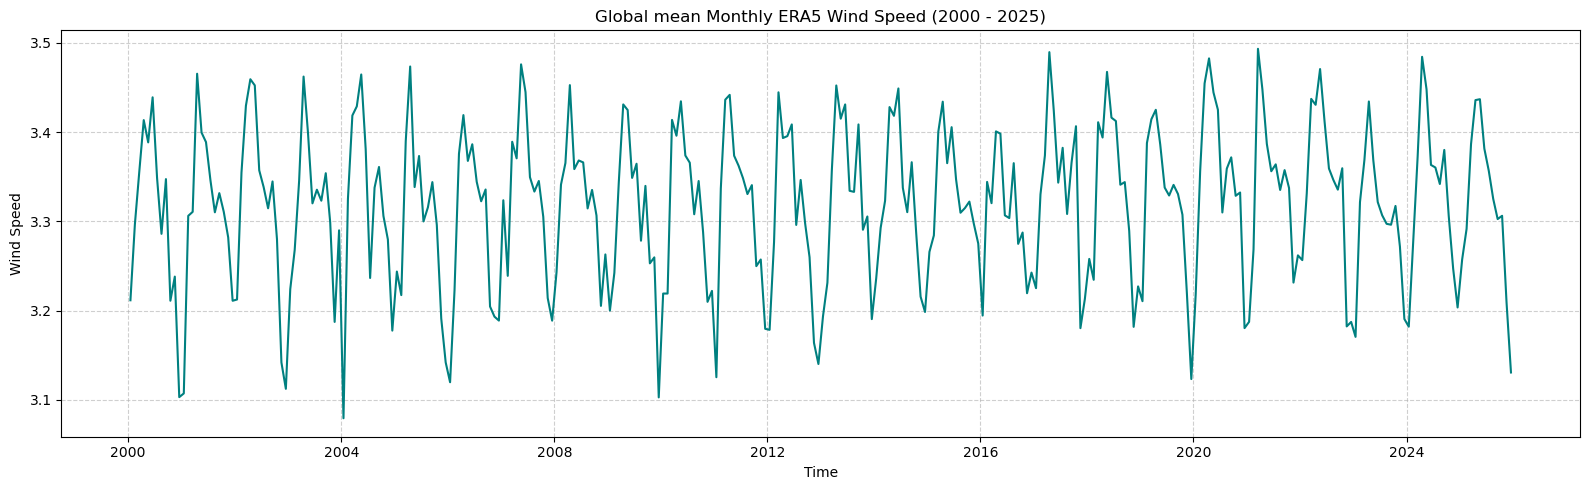

In [8]:
import matplotlib.pyplot as plt

# Calculate the global mean wind speed over time
global_mean_wind = (WIND2['WIND']*LandFrac1x1.LandArea).sum(dim=['latitude', 'longitude'])/LandFrac1x1.LandArea.sum(dim=['latitude', 'longitude'])

# Plot
plt.figure(figsize=(16, 5))
global_mean_wind.plot(color='teal', linewidth=1.5)

plt.title('Global mean Monthly ERA5 Wind Speed (2000 - 2025)')
plt.ylabel('Wind Speed')
plt.xlabel('Time')
plt.grid(True, linestyle='--', alpha=0.6)

# plt.xlim('2000-01-01', '2025-12-31')

plt.tight_layout()
plt.show()

In [9]:
# ---------------------------------------------------------
# Check for embedded NaNs in the WIND dataset
# ---------------------------------------------------------
print("--- Starting Embedded NaN Check for WIND ---")

# Dynamically grab the data variable (should be 'WIND' based on our generation script)
var_name = list(WIND.data_vars)[0]
da = WIND[var_name]

# Identify the total number of time steps
total_time_steps = len(da['time'])

# Count NaNs along the time dimension
nan_counts = da.isnull().sum(dim='time')

# Identify pixels with embedded NaNs (more than 0, but less than total time steps)
bad_pixels = (nan_counts > 0) & (nan_counts < total_time_steps)
num_bad_pixels = int(bad_pixels.sum().item())

# Print the results
if num_bad_pixels == 0:
    print(f"✅ WIND         (var: {var_name: <10}) | Clean! No embedded NaNs found.")
else:
    print(f"❌ WIND         (var: {var_name: <10}) | FOUND {num_bad_pixels} pixels with embedded NaNs.")

print("--- Check Complete ---")

--- Starting Embedded NaN Check for WIND ---
✅ WIND         (var: WIND      ) | Clean! No embedded NaNs found.
--- Check Complete ---
